# 06b · Real sarcasm: Qwen vs the circuit vs the custom mechanism (iSarcasmEval)

**Question:** is the circuit we found really better at handling sarcasm, or does a simple shortcut (the custom
mechanism) give the same result on real tweets?

**Data:** iSarcasmEval (SemEval 2022, task 6), English test set: **1400 tweets, 200 sarcastic** (labelled by their
authors), with the kind of each sarcastic tweet (sarcasm, irony, satire, ...), and **200 pairs** of a sarcastic
tweet and the author's own non-sarcastic rephrase. From the training set, 100 sarcastic + 600 non-sarcastic tweets
(the same 1 : 6 ratio as the test set) are used only for the mean of the circuit and for the threshold.

Every tweet goes into the same prompt as dataset v2: *Someone said: "…" Is this person being sarcastic? Answer
with Yes or No.*

| system | how it decides |
|---|---|
| **Qwen** | d > threshold (threshold chosen on the training tweets for the best F1, because only 1 in 7 is sarcastic) |
| **circuit** (8147 edges) | the same, answering alone (mean ablation; the mean is taken over the training tweets) |
| **mechanism** | segmenter c of 06a → phrase / situation; twitter-RoBERTa sentiment; sarcastic = positive phrase **and** negative situation |

**Runtime:** L4 ≈ 45–60 min (everything is cached: if Colab stops, rerun and it continues).
Needs from Drive: the circuit (02d), the sarcasm direction (03a) and the segments of 06a.

## Setup

In [1]:
import os, sys
REPO = "https://github.com/vasilis-pantzos/sarcasm-proposal.git"
ROOT = "/content/sarcasm-proposal"
if not os.path.exists(ROOT):
    !git clone -q {REPO} {ROOT}
else:
    !git -C {ROOT} pull -q
os.chdir(ROOT)
sys.path.insert(0, ROOT)
%pip install -q -U accelerate bitsandbytes
ISARC = "/content/iSarcasmEval"
if not os.path.exists(ISARC):
    !git clone -q https://github.com/iabufarha/iSarcasmEval.git {ISARC}

In [2]:
import os, json, time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from src.model import load_model, model_info, DEV_MODEL, MAIN_MODEL
from src.prompts import data_tag
from src.eap import build_graph
from src.standalone import ResampledReference, StandaloneEvaluator, standalone_d
from src.pathpatch import mean_last, ablate_d
from src.implicit import SARCASM_Q, IMPLICIT_Q, project_out_d
from src.baseline import cohen_kappa
from src.segment import load_isarcasm, CATEGORIES
from src.isarcasm import (tweet_ids, tweet_prompt, twitter_sentiment, mechanism, metrics, best_threshold,
                          pick_pair, clean)
from src.utils import mount_drive, results_dir, cached, set_seed

# ---------------- settings ----------------
MODEL = MAIN_MODEL
DATA = "v2"                              # the dataset the circuit was found on
CIRCUIT = "v3b/acdc_mask_tau0.0.npy"     # the final circuit (02d)
DIRECTION = "sarcasm_direction_L19.npy"  # from 03a
PROJECT_LAYERS = [19, 20, 21]
KEY_LAYER, KEY_HEADS = 18, [15, 18, 4, 13, 16]
N_RANDOM = 3                             # random controls in the causal test
N_TRAIN_SARC, N_TRAIN_NOT = 100, 600     # training tweets (mean of the circuit + threshold)
SEED = 0
# ------------------------------------------
TAG = MODEL.split("/")[-1] + data_tag(DATA)
SUB = f"06b_isarcasm/{TAG}"
mount_drive()
print("results go to:", results_dir(SUB))
set_seed(SEED)

Mounted at /content/drive
results go to: /content/drive/MyDrive/sarcasm/06b_isarcasm/Qwen2.5-7B-Instruct_data-v2


## 1 · Data and the segments of 06a

In [3]:
TEST, PAIRS, TRAIN = load_isarcasm(ISARC)
TEST["text"] = TEST.text.astype(str)
y = TEST.sarcastic.values.astype(bool)
TRAIN = TRAIN.dropna(subset=["tweet"])
TR = pd.concat([TRAIN[TRAIN.sarcastic == 1].sample(N_TRAIN_SARC, random_state=SEED),
                TRAIN[TRAIN.sarcastic == 0].sample(N_TRAIN_NOT, random_state=SEED)]).reset_index(drop=True)
y_tr = TR.sarcastic.values.astype(bool)
# the sarcastic and the non-sarcastic text of every pair
PAIRS["sarcastic"] = [r.text_0 if r.sarcastic_id == 0 else r.text_1 for r in PAIRS.itertuples()]
PAIRS["rephrase"] = [r.text_1 if r.sarcastic_id == 0 else r.text_0 for r in PAIRS.itertuples()]
print(f"test: {len(TEST)} tweets ({y.sum()} sarcastic) | pairs: {len(PAIRS)} | training tweets used: {len(TR)}")

seg_dir = "06a_segmenter"
load = lambda name: torch.load(os.path.join(results_dir(seg_dir), name + ".pt"), weights_only=False)
def segments(df):
    return pd.DataFrame({"text": df.text.values, "phrase": df.c_phrase.values, "situation": df.c_situation.values})
SEG = segments(load("segments_test"))
S0, S1 = segments(load("segments_pairs_text0")), segments(load("segments_pairs_text1"))
assert (SEG.text.values == TEST.text.values).all(), "the segments of 06a do not match the test set"
pick = lambda a, b, sid: pd.DataFrame([b.iloc[i] if s == 1 else a.iloc[i] for i, s in enumerate(sid)]).reset_index(drop=True)
SEG_PS = pick(S0, S1, PAIRS.sarcastic_id.values)            # segments of the sarcastic text of each pair
SEG_PR = pick(S1, S0, PAIRS.sarcastic_id.values)            # ... of the rephrase
print("segmenter c found both parts in", f"{(SEG.phrase.notna() & SEG.situation.notna()).mean():.2f}", "of the test tweets")

test: 1400 tweets (200 sarcastic) | pairs: 200 | training tweets used: 700
segmenter c found both parts in 0.87 of the test tweets


## 2 · The custom mechanism

twitter-RoBERTa (trained on tweets) gives p(negative), p(neutral), p(positive) for every phrase, situation and
whole tweet. Positive phrase = p(positive) > p(negative); negative situation = p(negative) > p(positive).

In [4]:
texts = set()
for s in (SEG, SEG_PS, SEG_PR):
    texts |= set(s.text) | set(s.phrase.dropna()) | set(s.situation.dropna())
texts = sorted(texts)
def run_sent():
    p = twitter_sentiment(texts)
    return {t: (a, b, c) for t, a, b, c in zip(texts, p["neg"], p["neu"], p["pos"])}
SENT = cached("sentiment", run_sent, sub=SUB)
torch.cuda.empty_cache()
MECH, MECH_PS, MECH_PR = mechanism(SEG, SENT), mechanism(SEG_PS, SENT), mechanism(SEG_PR, SENT)
print("mechanism says sarcastic:", int(MECH.sarcastic.sum()), "of", len(MECH), "tweets")
print(pd.crosstab(pd.Series(y, name="sarcastic (gold)"),
                  pd.Series(np.select([~MECH.found, MECH.sarcastic], ["parts not found", "contrast found"], "no contrast"),
                            name="mechanism")))

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

[saved]  /content/drive/MyDrive/sarcasm/06b_isarcasm/Qwen2.5-7B-Instruct_data-v2/sentiment.pt
mechanism says sarcastic: 175 of 1400 tweets
mechanism         contrast found  no contrast  parts not found
sarcastic (gold)                                              
False                        108          919              173
True                          67          124                9


## 3 · Qwen and the circuit on every tweet

In [5]:
t0 = time.time()
model, tok = load_model(MODEL)
G = build_graph(model)
print(MODEL, model_info(model), f"loaded in {(time.time() - t0) / 60:.1f} min")
path = os.path.join(results_dir(""), f"02_acdc/{TAG}/{CIRCUIT}")
assert os.path.exists(path), f"circuit not found: {path}"
MASK = np.load(path)
print(f"circuit: {int(MASK.sum())} edges")

IDS_TR, P0, S0_ = tweet_ids(tok, TR.tweet)
IDS_TE, P1, S1_ = tweet_ids(tok, TEST.text)
IDS_PS, P2, S2_ = tweet_ids(tok, PAIRS.sarcastic)
IDS_PR, P3, S3_ = tweet_ids(tok, PAIRS.rephrase)
PREFIX, SUFFIX = min(P0, P1, P2, P3), min(S0_, S1_, S2_, S3_)
print("template tokens before / after the tweet:", PREFIX, SUFFIX,
      "| prompt length: median", int(np.median([len(x) for x in IDS_TE])), "max", max(len(x) for x in IDS_TE))
print(tweet_prompt(TEST.text.iloc[0]))

t0 = time.time()
REF = ResampledReference(model, IDS_TR, G, prefix=PREFIX, suffix=SUFFIX)
print(f"mean reference: {len(IDS_TR)} training tweets, middle resampled to {REF.middle} positions | {time.time() - t0:.0f} s")

# sanity: all edges = the full model
T0 = pd.Series([len(x) for x in IDS_TE]).mode()[0]
part = [x for x in IDS_TE if len(x) == T0][:8]
ev = StandaloneEvaluator(model, tok, part, REF, G)
gap = np.abs(ev.d(G.valid) - ev.d_clean).max()
print(f"all edges: max |d - d_full| = {gap:.5f}")
assert gap < 1e-3, "sanity check failed: send the output to Claude"
del ev; torch.cuda.empty_cache()
print("PASS")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen/Qwen2.5-7B-Instruct {'n_layers': 28, 'n_heads': 28, 'n_kv_heads': 4, 'd_model': 3584, 'head_dim': 128} loaded in 1.1 min
circuit: 8147 edges
template tokens before / after the tweet: 27 18 | prompt length: median 65 max 193
Someone said: "Size on the the Toulouse team, That pack is monstrous. I can't see a Welsh region ever winning this, Money talks as they say ."
Is this person being sarcastic? Answer with Yes or No.
mean reference: 700 training tweets, middle resampled to 24 positions | 23 s
all edges: max |d - d_full| = 0.00000
PASS


In [6]:
t0 = time.time()
run = lambda ids: standalone_d(model, tok, ids, {"circuit": MASK}, REF, G, batch=16, progress=False)
D_TR = cached("d_train", lambda: run(IDS_TR), sub=SUB)
D_TE = cached("d_test", lambda: run(IDS_TE), sub=SUB)
D_PS = cached("d_pairs_sarcastic", lambda: run(IDS_PS), sub=SUB)
D_PR = cached("d_pairs_rephrase", lambda: run(IDS_PR), sub=SUB)
print(f"{(time.time() - t0) / 60:.1f} min")

THR = {k: best_threshold(D_TR[k], y_tr) for k in ["full", "circuit"]}
print("thresholds (best F1 on the training tweets):", {k: round(v, 2) for k, v in THR.items()})
print("for reference, Qwen with d > 0 on the test set:", {k: round(v, 3) for k, v in metrics(D_TE["full"] > 0, y).items()})
TEST["d Qwen"], TEST["d circuit"] = D_TE["full"], D_TE["circuit"]
YES = {"Qwen": D_TE["full"] > THR["full"], "circuit": D_TE["circuit"] > THR["circuit"],
       "mechanism": MECH.sarcastic.values}

[saved]  /content/drive/MyDrive/sarcasm/06b_isarcasm/Qwen2.5-7B-Instruct_data-v2/d_train.pt
[saved]  /content/drive/MyDrive/sarcasm/06b_isarcasm/Qwen2.5-7B-Instruct_data-v2/d_test.pt
[saved]  /content/drive/MyDrive/sarcasm/06b_isarcasm/Qwen2.5-7B-Instruct_data-v2/d_pairs_sarcastic.pt
[saved]  /content/drive/MyDrive/sarcasm/06b_isarcasm/Qwen2.5-7B-Instruct_data-v2/d_pairs_rephrase.pt
4.6 min
thresholds (best F1 on the training tweets): {'full': 0.59, 'circuit': 7.04}
for reference, Qwen with d > 0 on the test set: {'F1': 0.404, 'precision': 0.289, 'recall': 0.67, 'accuracy': 0.718, 'said Yes': 0.331}


## 4 · Main table

F1, precision and recall of the **sarcastic** class (the usual measure in iSarcasmEval; the best systems of the
competition reached F1 ≈ 0.6), accuracy, the share of tweets answered "sarcastic", and Cohen's κ with Qwen.

In [7]:
MAIN = pd.DataFrame({k: {**metrics(v, y), "κ with Qwen": cohen_kappa(v, YES["Qwen"])} for k, v in YES.items()}).T
display(MAIN.round(3))

,F1,precision,recall,accuracy,said Yes,κ with Qwen
Qwen,0.410,0.300,0.650,0.733,0.310,1.000
circuit,0.387,0.352,0.430,0.806,0.174,0.506
mechanism,0.357,0.383,0.335,0.828,0.125,0.099


## 5 · Where do they differ?

**(a)** On the sarcastic tweets: which ones each system finds. **(b)** Recall per kind of sarcasm. **(c)** The
key split: tweets where the mechanism finds the contrast "positive phrase + negative situation" and all the others.
If Qwen is only a better version of the shortcut, its advantage should be inside the contrast group; if it handles
sarcasm the shortcut cannot see, it should also find sarcastic tweets outside it.

In [8]:
q, m, c = YES["Qwen"], YES["mechanism"], YES["circuit"]
print("(a) sarcastic tweets found (of", y.sum(), ")")
display(pd.crosstab(pd.Series(np.where(q[y], "Qwen: yes", "Qwen: no"), name=""),
                    pd.Series(np.where(m[y], "mechanism: yes", "mechanism: no"), name="")))

rows = []
for cat in CATEGORIES:
    k = (TEST[cat] == 1).values & y
    if k.sum():
        rows.append({"kind": cat, "n": int(k.sum()), **{s: float(v[k].mean()) for s, v in YES.items()}})
CAT = pd.DataFrame(rows).set_index("kind")
print("(b) recall per kind of sarcasm")
display(CAT.round(2))

CONTRAST = MECH.sarcastic.values
rows = []
for name, g in [("contrast found", CONTRAST), ("no contrast", ~CONTRAST)]:
    for s in ["Qwen", "circuit"]:
        rows.append({"group": name, "system": s, "tweets": int(g.sum()), "sarcastic": int(y[g].sum()),
                     "recall": float(YES[s][g & y].mean()) if (g & y).any() else np.nan,
                     "said Yes to non-sarcastic": float(YES[s][g & ~y].mean()) if (g & ~y).any() else np.nan})
SPLIT = pd.DataFrame(rows).set_index(["group", "system"])
print("(c) inside / outside the contrast group")
display(SPLIT.round(3))
print(f"share of all sarcastic tweets that are in the contrast group: {CONTRAST[y].mean():.2f}")

(a) sarcastic tweets found (of 200 )


,mechanism: no,mechanism: yes
,,
Qwen: no,53,17
Qwen: yes,80,50


(b) recall per kind of sarcasm


,n,Qwen,circuit,mechanism
kind,,,,
sarcasm,180,0.68,0.46,0.32
irony,20,0.35,0.15,0.50
satire,49,0.31,0.24,0.27
understatement,1,1.00,1.00,0.00
overstatement,10,0.50,0.30,0.20
rhetorical_question,11,0.91,0.55,0.09


(c) inside / outside the contrast group


tweets  sarcastic  recall  said Yes to non-sarcastic
group          system                                                       
contrast found Qwen        175         67   0.746                      0.269
               circuit     175         67   0.537                      0.167
no contrast    Qwen       1225        133   0.602                      0.252
               circuit    1225        133   0.376                      0.128

share of all sarcastic tweets that are in the contrast group: 0.34


## 6 · Pairs: detection and interpretation

**Detection** (task C of iSarcasmEval): which of the two texts is the sarcastic one? Qwen and the circuit pick the
text with the higher d, the mechanism the text with the higher score p(positive phrase) · p(negative situation)
(a tie counts as half).

**Interpretation:** the implicit question of phase 5, *"Is this person actually happy about it?"*, on the sarcastic
tweet and on the author's rephrase. The rephrase says what the author meant, so a system that understands the
sarcasm gives the **same** answer to both. The mechanism answers with the sentiment of the situation (of the whole
text if no parts were found); the **literal** reader answers with the sentiment of the whole text.

In [9]:
DET = {"Qwen": pick_pair(D_PR["full"], D_PS["full"]), "circuit": pick_pair(D_PR["circuit"], D_PS["circuit"]),
       "mechanism": pick_pair(MECH_PR.score, MECH_PS.score)}
DET = pd.Series({k: float(v.mean()) for k, v in DET.items()}, name="detection accuracy")

IMP_TR, a0, b0 = tweet_ids(tok, TR.tweet, IMPLICIT_Q)
IMP_PS, a1, b1 = tweet_ids(tok, PAIRS.sarcastic, IMPLICIT_Q)
IMP_PR, a2, b2 = tweet_ids(tok, PAIRS.rephrase, IMPLICIT_Q)
t0 = time.time()
REF_IMP = ResampledReference(model, IMP_TR, G, prefix=min(a0, a1, a2), suffix=min(b0, b1, b2))
runi = lambda ids: standalone_d(model, tok, ids, {"circuit": MASK}, REF_IMP, G, batch=16, progress=False)
DI_PS = cached("d_implicit_pairs_sarcastic", lambda: runi(IMP_PS), sub=SUB)
DI_PR = cached("d_implicit_pairs_rephrase", lambda: runi(IMP_PR), sub=SUB)
print(f"{(time.time() - t0) / 60:.1f} min")

HAPPY = {"Qwen": (DI_PS["full"] > 0, DI_PR["full"] > 0), "circuit": (DI_PS["circuit"] > 0, DI_PR["circuit"] > 0),
         "mechanism": (MECH_PS.happy.values, MECH_PR.happy.values),
         "literal": (MECH_PS["literal happy"].values, MECH_PR["literal happy"].values)}
PAIR = pd.DataFrame({k: {"same answer to both": float((a == b).mean()), "'not happy' on the sarcastic tweet": float((~a).mean()),
                         "'not happy' on the rephrase": float((~b).mean())} for k, (a, b) in HAPPY.items()}).T
PAIR["detection accuracy"] = DET
display(PAIR.round(3))

[saved]  /content/drive/MyDrive/sarcasm/06b_isarcasm/Qwen2.5-7B-Instruct_data-v2/d_implicit_pairs_sarcastic.pt
[saved]  /content/drive/MyDrive/sarcasm/06b_isarcasm/Qwen2.5-7B-Instruct_data-v2/d_implicit_pairs_rephrase.pt
1.3 min


,same answer to both,'not happy' on the sarcastic tweet,'not happy' on the rephrase,detection accuracy
Qwen,0.830,0.875,0.955,0.770
circuit,0.935,0.955,0.970,0.715
mechanism,0.650,0.425,0.545,0.690
literal,0.365,0.330,0.825,NaN


## 7 · Causal test on Qwen: does it use the mechanism we found on real tweets?

As in phase 5: remove the sarcasm direction (layers 19–21) or the layer-18 writers (m18 + 5 key heads), against
random controls. Same threshold as before. If the found mechanism is what Qwen uses for real contrast sarcasm, the
recall should drop **mostly inside the contrast group**.

In [10]:
pdir = os.path.join(results_dir(""), f"03a_direction/{TAG}/{DIRECTION}")
assert os.path.exists(pdir), f"direction not found: {pdir}"
U = np.load(pdir).astype(np.float32)
rng = np.random.default_rng(0)
RAND_DIRS = [rng.standard_normal(U.shape).astype(np.float32) for _ in range(N_RANDOM)]
H = model_info(model)["n_heads"]
RAND_HEADS = [sorted(rng.choice([h for h in range(H) if h not in KEY_HEADS], 5, replace=False).tolist())
              for _ in range(N_RANDOM)]

def ablations():
    z, mm = mean_last(model, IDS_TR, KEY_LAYER)
    out = {"direction (L19-21)": project_out_d(model, tok, IDS_TE, PROJECT_LAYERS, U),
           "writers (m18 + 5 heads)": ablate_d(model, tok, IDS_TE, KEY_LAYER, KEY_HEADS, True, z, mm)}
    for i, v in enumerate(RAND_DIRS):
        out[f"random direction #{i}"] = project_out_d(model, tok, IDS_TE, PROJECT_LAYERS, v)
    for i, hs in enumerate(RAND_HEADS):
        out[f"random 5 heads #{i}"] = ablate_d(model, tok, IDS_TE, KEY_LAYER, hs, False, z, mm)
    return out

t0 = time.time()
ABL = {"none": D_TE["full"], **cached("ablations", ablations, sub=SUB)}
print(f"{(time.time() - t0) / 60:.1f} min")
rows = []
for k, d in ABL.items():
    yes = d > THR["full"]
    rows.append({"ablation": k, "F1": metrics(yes, y)["F1"],
                 "recall: contrast found": float(yes[CONTRAST & y].mean()),
                 "recall: no contrast": float(yes[~CONTRAST & y].mean()),
                 "said Yes to non-sarcastic": float(yes[~y].mean()),
                 "mean d (sarcastic)": float(d[y].mean())})
CAUS = pd.DataFrame(rows).set_index("ablation")
display(CAUS.round(3))

[saved]  /content/drive/MyDrive/sarcasm/06b_isarcasm/Qwen2.5-7B-Instruct_data-v2/ablations.pt
5.5 min


,F1,recall: contrast found,recall: no contrast,said Yes to non-sarcastic,mean d (sarcastic)
ablation,,,,,
none,0.410,0.746,0.602,0.253,4.815
direction (L19-21),0.310,0.851,0.752,0.546,7.688
writers (m18 + 5 heads),0.416,0.642,0.451,0.160,1.057
random direction #0,0.406,0.746,0.602,0.258,4.913
random direction #1,0.408,0.746,0.602,0.256,4.822
random direction #2,0.405,0.746,0.602,0.260,4.994
random 5 heads #0,0.414,0.761,0.617,0.258,5.105
random 5 heads #1,0.414,0.761,0.609,0.255,4.865
random 5 heads #2,0.411,0.746,0.602,0.252,4.688


## 8 · Figure

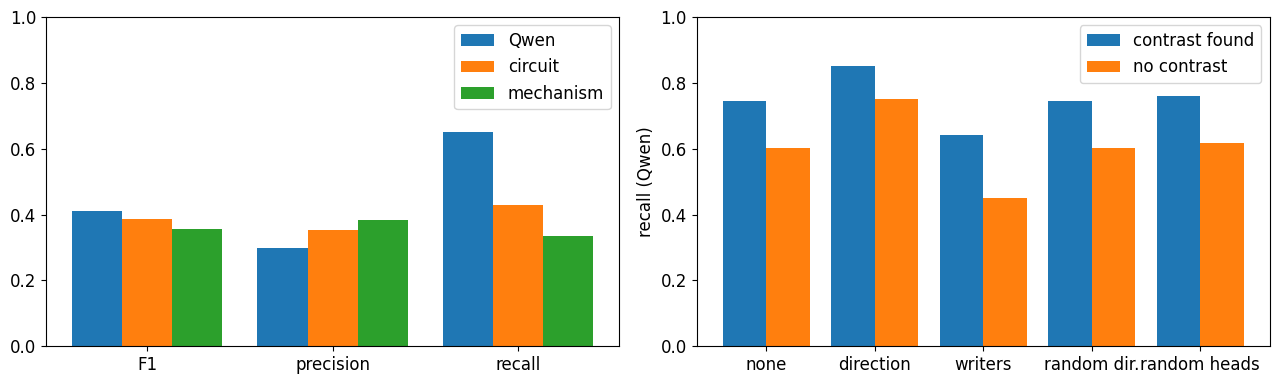

In [11]:
plt.rcParams.update({"font.size": 12})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
x = np.arange(3)
for j, s in enumerate(YES):
    ax.bar(x + (j - 1) * 0.27, MAIN.loc[s, ["F1", "precision", "recall"]], 0.27, label=s)
ax.set_xticks(x); ax.set_xticklabels(["F1", "precision", "recall"]); ax.set_ylim(0, 1); ax.legend()
ax = axes[1]
keys = ["none", "direction (L19-21)", "writers (m18 + 5 heads)", "random direction #0", "random 5 heads #0"]
x = np.arange(len(keys))
ax.bar(x - 0.2, CAUS.loc[keys, "recall: contrast found"], 0.4, label="contrast found")
ax.bar(x + 0.2, CAUS.loc[keys, "recall: no contrast"], 0.4, label="no contrast")
ax.set_xticks(x); ax.set_xticklabels(["none", "direction", "writers", "random dir.", "random heads"])
ax.set_ylabel("recall (Qwen)"); ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "isarcasm.png"), dpi=200); plt.show()

## 9 · Examples where Qwen and the mechanism disagree (sarcastic tweets)

In [12]:
pd.set_option("display.max_colwidth", 90)
EX = pd.DataFrame({"tweet": TEST.text, "phrase": SEG.phrase, "situation": SEG.situation,
                   "d Qwen": TEST["d Qwen"].round(2), "Qwen": YES["Qwen"], "mechanism": YES["mechanism"]})
print("Qwen finds it, the mechanism does not:")
display(EX[y & q & ~m].head(8))
print("the mechanism finds it, Qwen does not:")
display(EX[y & ~q & m].head(8))
print("the mechanism says sarcastic, but the tweet is not:")
display(EX[~y & m].head(5))

Qwen finds it, the mechanism does not:


,tweet,phrase,situation,d Qwen,Qwen,mechanism
2,So the Scottish Government want people to get their booster shots so badly that the we...,So the … so badly that the website doesn't even work,get their booster shots,5.39,True,False
21,"Max Verstappen is such a clean driver, he never makes dirty moves when racing.",is such … he never makes dirty moves when,a clean driver,0.99,True,False
47,"Wow the Prime Minister is so good at the telling the truth, yet again he just can't st...","Wow the … is so good at the telling the truth, yet again he just can't stop telling th...",Prime Minister,16.90,True,False
63,"if you listen carefully, you can hear me not carig","if you listen carefully, you can hear me not carig",None,5.14,True,False
87,"The Spanish National Ballet company rehearsing wearing masks: gasping, falling about c...",Makes sense that you'd refuse to … Totally. Carry on.,The Spanish National Ballet company rehearsing wearing masks: gasping,13.03,True,False
89,I just can’t wait to spend time with my family over Christmas! I just love being the o...,I just love being the … the many many questions asking when will I,spend time with my family over Christmas,2.92,True,False
102,Been looking forward to today all weekend. Mondays are the best. I feel fresh and re...,Been looking forward to … Mondays are the best. I feel fresh and ready to start the w...,today all weekend,19.11,True,False
127,Government- “all over 40’s must have booster jab by end of January!” NHS website *rubs...,website *rubs … together in glee* “oh yes? I think not…,end of January,19.83,True,False


the mechanism finds it, Qwen does not:


,tweet,phrase,situation,d Qwen,Qwen,mechanism
35,Boris looked so statesman-like in that public address,Boris looked so statesman-like,in that public address,-4.32,False,True
56,It makes me feel a lot safer knowing the MET Police don't investigate crimes after the...,It makes me feel a lot safer knowing … after they happen.,the MET Police,0.21,False,True
84,"Yeah, feeding children sweets before bedtime is an awesome way of getting lots of sleep","Yeah, … is an awesome way of getting lots",feeding children sweets before bedtime,0.08,False,True
606,"Love how modern society has the same rules for everyone, regardless of your job or bac...","has the same rules for everyone, regardless of … Really brings the country together",your job or background,-6.03,False,True
669,"Vaccine mandates are obviously great things for the good of the people, cause nothing ...","are obviously great things for the good of the people, cause nothing bad has ever happ...",Vaccine mandates,-9.29,False,True
760,I just love going out in the rain. It is so nice going to the park when it is pouring ...,It is so nice going … It is so cool to,get mud in your hair and your socks drenched,-13.75,False,True
761,so lovely to see that the government continues to prioritise the safety of disabled pe...,so lovely to see that the government continues to prioritise the,safety of disabled people,-5.63,False,True
765,I would like to offer my complete support for the new rules as they have obviously sup...,I would like to offer my complete support for … as they have obviously supported the p...,the new rules,-9.12,False,True


the mechanism says sarcastic, but the tweet is not:


,tweet,phrase,situation,d Qwen,Qwen,mechanism
13,"Wow, Chelsea bean beaten by West Ham, that was a day I had been looking forward to for...","Wow, … that was a day I had been looking forward to for a while.",Chelsea bean beaten by West Ham,0.15,False,True
18,Beauty of wearing a mask isn’t that it’s just the responsible thing to do is that it’s...,Beauty of … isn’t that it’s just the responsible thing to do is that it’s another laye...,warmth on my freezing trips to work,-9.89,False,True
28,Brrrr it's cold outside...\n\nI love it!,it's … I love it,cold outside,-3.28,False,True
41,i would’ve sold my kidney to be there,i would’ve sold … to be,my kidney,-8.63,False,True
52,From the wilds of Africa,From,the wilds of Africa,-11.51,False,True


## Save

In [13]:
d = results_dir(SUB)
out = TEST[["text", "sarcastic", *CATEGORIES, "d Qwen", "d circuit"]].copy()
out["phrase"], out["situation"] = SEG.phrase, SEG.situation
for k, v in YES.items():
    out[f"yes {k}"] = v
out["contrast found"] = CONTRAST
out.to_csv(os.path.join(d, "per_tweet.csv"), index=False)
for name, t in [("main", MAIN), ("per_kind", CAT), ("contrast_split", SPLIT), ("pairs", PAIR), ("causal", CAUS)]:
    t.to_csv(os.path.join(d, f"{name}.csv"))
json.dump(THR, open(os.path.join(d, "thresholds.json"), "w"))
print("saved to", d)

saved to /content/drive/MyDrive/sarcasm/06b_isarcasm/Qwen2.5-7B-Instruct_data-v2
